In [5]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [6]:

def generate_chaotic_values(KEY, size,dt=0.01):
    step=size//4+1
    x0, y0, z0, u0=KEY["coordinates"]
    sigma, rho, beta, k=KEY["parameter"]
    x = np.zeros(step)
    y = np.zeros(step)
    z = np.zeros(step)
    u = np.zeros(step)
    x[0], y[0], z[0], u[0] = x0, y0, z0, u0
   
    for n in range(step - 1):
        x[n+1] = x[n] + sigma * (y[n] - x[n]) * dt + u[n] * dt
        y[n+1] = y[n] + (x[n] * (rho - z[n]) - y[n]) * dt
        z[n+1] = z[n] + (x[n] * y[n] - beta * z[n]) * dt
        u[n+1] = -k * x[n] * dt
   
    return np.concatenate((x, y, z, u))[:size]

In [7]:
KEY = {
    "coordinates": [7.438912, -5.239871, 9.183740, -3.182937],
    "parameter": (10.0, 28.0, 8/3, 1.0),   
}

In [8]:
def Encrypt(image, KEY):
    length, width, height = image.shape
    size = length * width * height
    flat = image.flatten().astype(np.int64)

  
    key = generate_chaotic_values(KEY, size)

    scramble = np.argsort(key)
    flat = flat[scramble]

    
    diffusion_key = ((key * 1e12) % 256).astype(np.int64)
    diffusion_forward = ((key * 1e9) % 256).astype(np.int64)
    diffusion_backward = ((key * 1e6) % 256).astype(np.int64)

  
    flat = np.bitwise_xor(flat, diffusion_key)

   
    flat = np.cumsum(flat + diffusion_forward) % 256

    
    flat = (np.cumsum(flat[::-1] + diffusion_backward[::-1]) % 256)[::-1]

    encrypted_img = flat.astype(np.uint8).reshape(length, width, height)
    return encrypted_img


def Decrypt(encrypted_img, KEY):
    length, width, channels = encrypted_img.shape
    size = length * width * channels
    flat = encrypted_img.flatten().astype(np.int64)

   
    key = generate_chaotic_values(KEY, size)

    diffusion_key = ((key * 1e12) % 256).astype(np.int64)
    diffusion_forward = ((key * 1e9) % 256).astype(np.int64)
    diffusion_backward = ((key * 1e6) % 256).astype(np.int64)

   
    rev_backward = flat[::-1]
    diff_backward = np.diff(rev_backward, prepend=0) % 256
    flat = ((diff_backward - diffusion_backward[::-1]) % 256)[::-1]

    
    diff_forward = np.diff(flat, prepend=0) % 256
    flat = (diff_forward - diffusion_forward) % 256

   
    flat = np.bitwise_xor(flat, diffusion_key)

   
    scramble = np.argsort(key)
    unscramble = np.argsort(scramble)
    flat = flat[unscramble]

    decrypted_img = flat.astype(np.uint8).reshape(length, width, channels)
    return decrypted_img

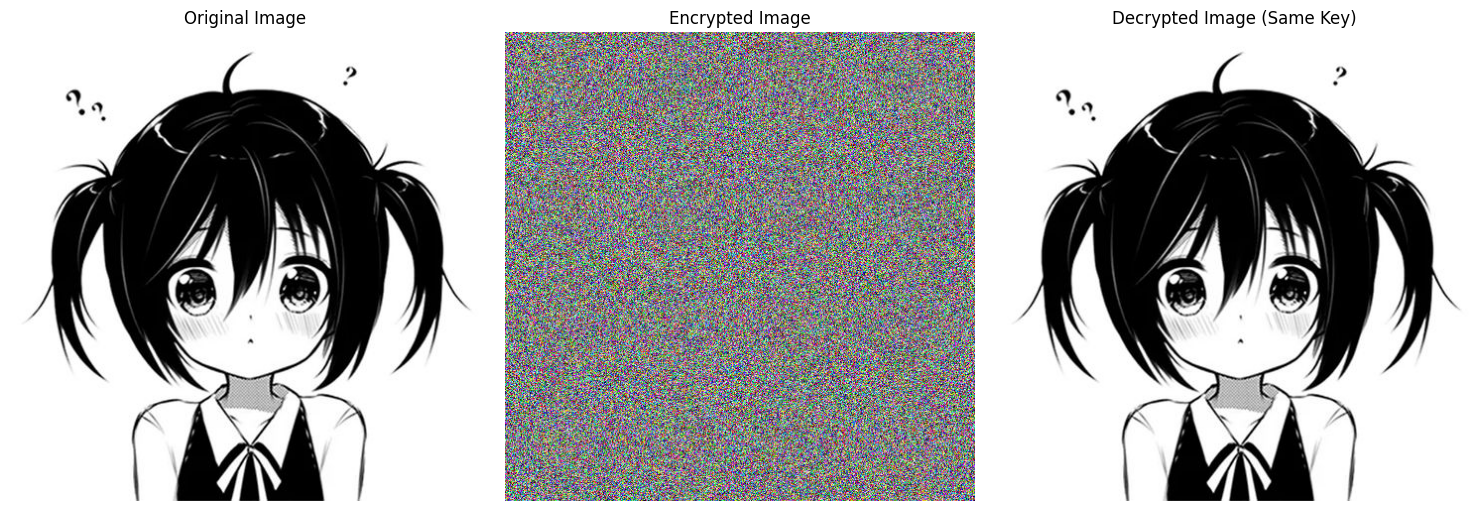

In [9]:
img_path = 'input1.jpg'
img = np.array(Image.open(img_path))
encrypted_img = Encrypt(img,KEY)
decrypted_img = Decrypt(encrypted_img,KEY)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(encrypted_img)
plt.title("Encrypted Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(decrypted_img)
plt.title("Decrypted Image (Same Key)")
plt.axis("off")

plt.tight_layout()
plt.show()

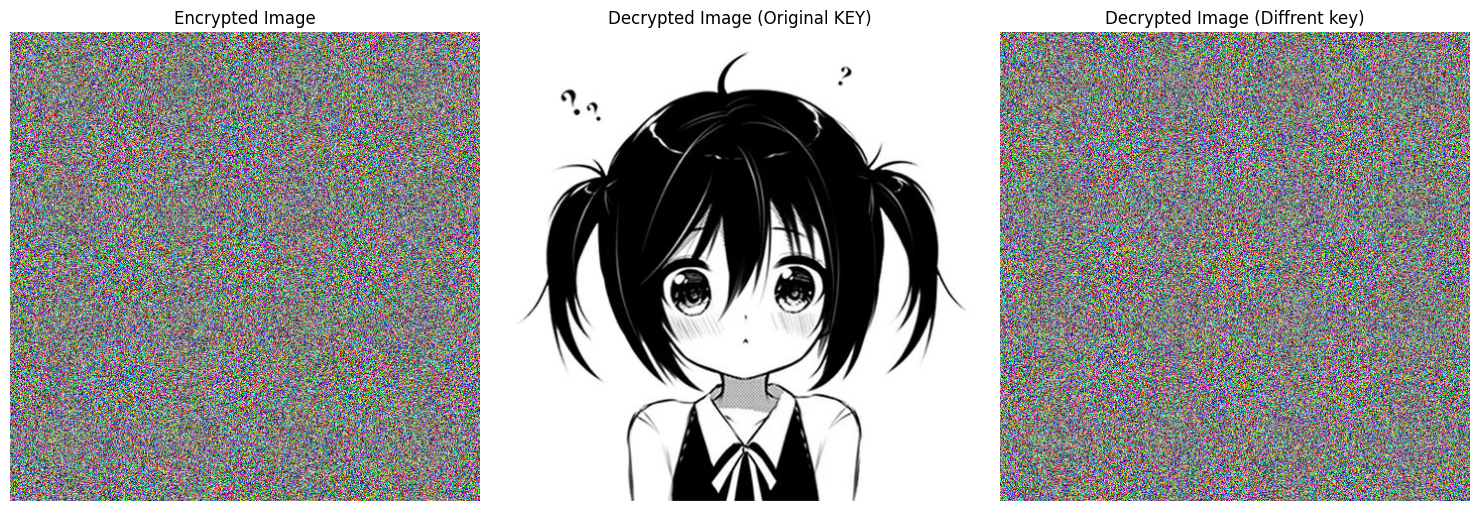

In [10]:
new_x0=KEY["coordinates"][0]+1e-10
KEY1 = {
    "coordinates": [7.438912, -5.239871, 9.183740, -3.182937],
    "parameter": (28.0, 6.7, 72.0, 14.0),                  
}
KEY1["coordinates"][0]=new_x0
decrypted_img_wrong_key = Decrypt(encrypted_img,KEY1)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(encrypted_img)
plt.title("Encrypted Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(decrypted_img)
plt.title("Decrypted Image (Original KEY)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(decrypted_img_wrong_key)
plt.title("Decrypted Image (Diffrent key)")
plt.axis("off")

plt.tight_layout()
plt.show()

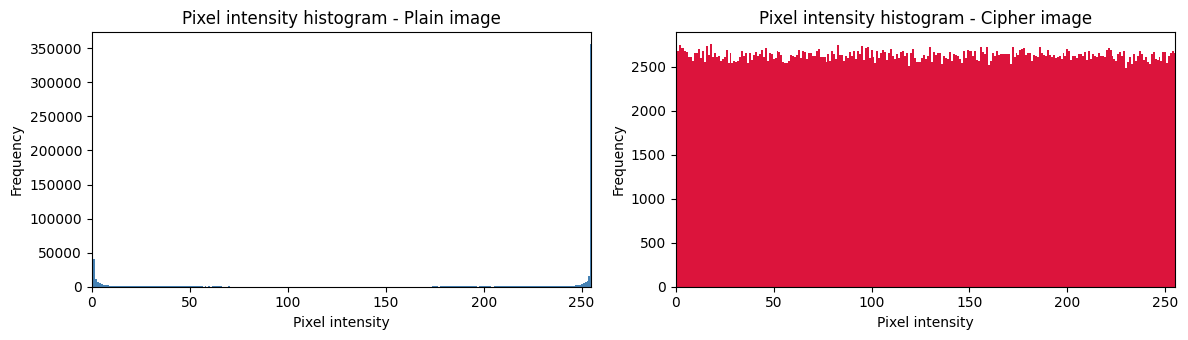

In [11]:

DIRECTIONS = ["Horizontal", "Vertical", "Diagonal", "Anti-diagonal"]
 
def _is_rgb(im):
    return im.ndim == 3 and im.shape[2] == 3
 
def _names(im):
    return (["Red", "Green", "Blue"], ["red", "green", "blue"]) if _is_rgb(im) else (["Gray"], ["gray"])
 
def channels(im):
    return [im[..., c] for c in range(3)] if im.ndim == 3 else [im]
 
def histogram(x):
    return np.bincount(x.reshape(-1), minlength=256)
 
def entropy(x):
    p = histogram(x) / x.size
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())
 
def pairs(g, direction):
    g = g.astype(np.float64)
    if direction == "Horizontal":    return g[:, :-1],   g[:, 1:]
    if direction == "Vertical":      return g[:-1, :],   g[1:, :]
    if direction == "Diagonal":      return g[:-1, :-1], g[1:, 1:]
    if direction == "Anti-diagonal": return g[:-1, 1:],  g[1:, :-1]
 
def corr_coef(g, direction):
    first, second = pairs(g, direction)
    first, second = first.reshape(-1), second.reshape(-1)
    if first.std() == 0 or second.std() == 0:
        return 0.0
    return float(np.corrcoef(first, second)[0, 1])
 
 
# %% ---------- 1. Pixel intensity histogram ----------
def plot_intensity_histogram(plain, cipher):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for axis, im, title, color in zip(axes, [plain, cipher], ["Plain image", "Cipher image"], ["steelblue", "crimson"]):
        axis.bar(np.arange(256), histogram(im), width=1.0, color=color)
        axis.set_title(f"Pixel intensity histogram - {title}")
        axis.set_xlabel("Pixel intensity"); axis.set_ylabel("Frequency"); axis.set_xlim(0, 255)
    plt.tight_layout(); plt.show()
 
 
# %% ---------- 2. Three-channel (R, G, B) histograms ----------
def plot_channel_histograms(plain, cipher):
    names, colors = _names(plain)
    if len(names) == 1:
        print("Image is not RGB - showing the single gray channel only.")
    fig, axes = plt.subplots(2, len(names), figsize=(5 * len(names), 6), squeeze=False)
    for row, (im, label) in enumerate([(plain, "Plain"), (cipher, "Cipher")]):
        for col, chan in enumerate(channels(im)):
            axes[row, col].bar(np.arange(256), histogram(chan), width=1.0, color=colors[col])
            axes[row, col].set_title(f"{label} - {names[col]} channel")
            axes[row, col].set_xlabel("Pixel intensity"); axes[row, col].set_ylabel("Frequency")
            axes[row, col].set_xlim(0, 255)
    plt.tight_layout(); plt.show()
 
 
# %% ---------- 3. Pixel correlation scatter plots (adjacent pairs) ----------
def plot_correlation_scatter(plain, cipher, channel=0, n_points=3000, seed=1):
    """channel: 0=R, 1=G, 2=B (ignored for gray images)."""
    names, _ = _names(plain)
    channel = channel if len(names) == 3 else 0
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for row, (im, label, color) in enumerate([(plain, "Plain", "steelblue"), (cipher, "Cipher", "crimson")]):
        g = channels(im)[channel]
        for col, direction in enumerate(["Horizontal", "Vertical", "Diagonal"]):
            first, second = pairs(g, direction)
            first, second = first.reshape(-1), second.reshape(-1)
            idx = rng.integers(0, first.size, min(n_points, first.size))
            axes[row, col].scatter(first[idx], second[idx], s=3, color=color, alpha=0.6)
            axes[row, col].set_title(f"{label} - {direction}  (r = {corr_coef(g, direction):.4f})")
            axes[row, col].set_xlabel("Pixel value at (x, y)"); axes[row, col].set_ylabel("Adjacent pixel value")
            axes[row, col].set_xlim(0, 255); axes[row, col].set_ylim(0, 255)
    plt.suptitle(f"Adjacent-pixel correlation - {names[channel]} channel", y=1.0)
    plt.tight_layout(); plt.show()
 
 
# %% ---------- 4. Multi-directional correlation coefficients (all channels) ----------
def plot_multidirectional_correlation(plain, cipher):
    names, _ = _names(plain)
    fig, axes = plt.subplots(1, len(names), figsize=(5.5 * len(names), 4), squeeze=False)
    print(f"{'Channel':8s}{'Direction':15s}{'Plain':>10s}{'Cipher':>10s}")
    for ci, name in enumerate(names):
        plain_c  = [corr_coef(channels(plain)[ci],  d) for d in DIRECTIONS]
        cipher_c = [corr_coef(channels(cipher)[ci], d) for d in DIRECTIONS]
        for d, pv, cv in zip(DIRECTIONS, plain_c, cipher_c):
            print(f"{name:8s}{d:15s}{pv:10.4f}{cv:10.4f}")
        xs, width = np.arange(len(DIRECTIONS)), 0.38
        axes[0, ci].bar(xs - width/2, plain_c,  width, label="Plain",  color="steelblue")
        axes[0, ci].bar(xs + width/2, cipher_c, width, label="Cipher", color="crimson")
        axes[0, ci].set_xticks(xs); axes[0, ci].set_xticklabels(DIRECTIONS, rotation=20)
        axes[0, ci].set_ylim(-1.05, 1.05); axes[0, ci].axhline(0, color="black", lw=0.8)
        axes[0, ci].set_title(f"{name} channel"); axes[0, ci].set_ylabel("Correlation coefficient")
        axes[0, ci].legend()
    plt.suptitle("Multi-directional correlation (ideal cipher value ~ 0)", y=1.02)
    plt.tight_layout(); plt.show()
 
 
# %% ---------- 5. Information entropy ----------
def plot_entropy(plain, cipher):
    names, _ = _names(plain)
    plain_e  = [entropy(c) for c in channels(plain)]  + [entropy(plain)]
    cipher_e = [entropy(c) for c in channels(cipher)] + [entropy(cipher)]
    labels = names + ["Overall"]
    for label, pv, cv in zip(labels, plain_e, cipher_e):
        print(f"{label:8s} plain = {pv:.4f}   cipher = {cv:.4f}   (ideal = 8)")
    xs, width = np.arange(len(labels)), 0.38
    plt.figure(figsize=(7, 4))
    plt.bar(xs - width/2, plain_e,  width, label="Plain",  color="steelblue")
    plt.bar(xs + width/2, cipher_e, width, label="Cipher", color="crimson")
    plt.axhline(8, color="black", ls="--", lw=1, label="Ideal = 8")
    plt.xticks(xs, labels); plt.ylim(0, 8.6); plt.ylabel("Entropy (bits)")
    plt.title("Information entropy"); plt.legend(); plt.tight_layout(); plt.show()
 
 
# %% ---------- 6. NPCR and UACI (differential attack) ----------
def plot_npcr_uaci(plain, cipher, encrypt_fn, n_trials=10, seed=7):
    """One random pixel value is changed by +1, the image is encrypted again with the SAME key,
    and the two cipher images are compared. Each trial calls encrypt_fn once."""
    rng = np.random.default_rng(seed)
    npcr_list, uaci_list = [], []
    flat_plain = plain.reshape(-1)
    for _ in range(n_trials):
        changed = flat_plain.copy()
        pos = rng.integers(0, changed.size)
        changed[pos] = (int(changed[pos]) + 1) % 256
        cipher2 = encrypt_fn(changed.reshape(plain.shape),KEY)
        diff = np.abs(cipher.astype(np.int64) - cipher2.astype(np.int64))
        npcr_list.append(np.mean(diff != 0) * 100)
        uaci_list.append(np.mean(diff) / 255 * 100)
 
    print(f"NPCR mean = {np.mean(npcr_list):.4f} %   (ideal 99.6094 %)")
    print(f"UACI mean = {np.mean(uaci_list):.4f} %   (ideal 33.4635 %)")
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(npcr_list, "o-", color="darkorange"); axes[0].axhline(99.6094, color="black", ls="--", label="Ideal 99.6094%")
    axes[0].set_title("NPCR per trial"); axes[0].set_xlabel("Trial"); axes[0].set_ylabel("NPCR (%)"); axes[0].legend()
    axes[1].plot(uaci_list, "o-", color="seagreen");   axes[1].axhline(33.4635, color="black", ls="--", label="Ideal 33.4635%")
    axes[1].set_title("UACI per trial"); axes[1].set_xlabel("Trial"); axes[1].set_ylabel("UACI (%)"); axes[1].legend()
    plt.tight_layout(); plt.show()
 
 
# %% ---------- RUN (one call per cell, or all together) ----------
plot_intensity_histogram(img, encrypted_img)

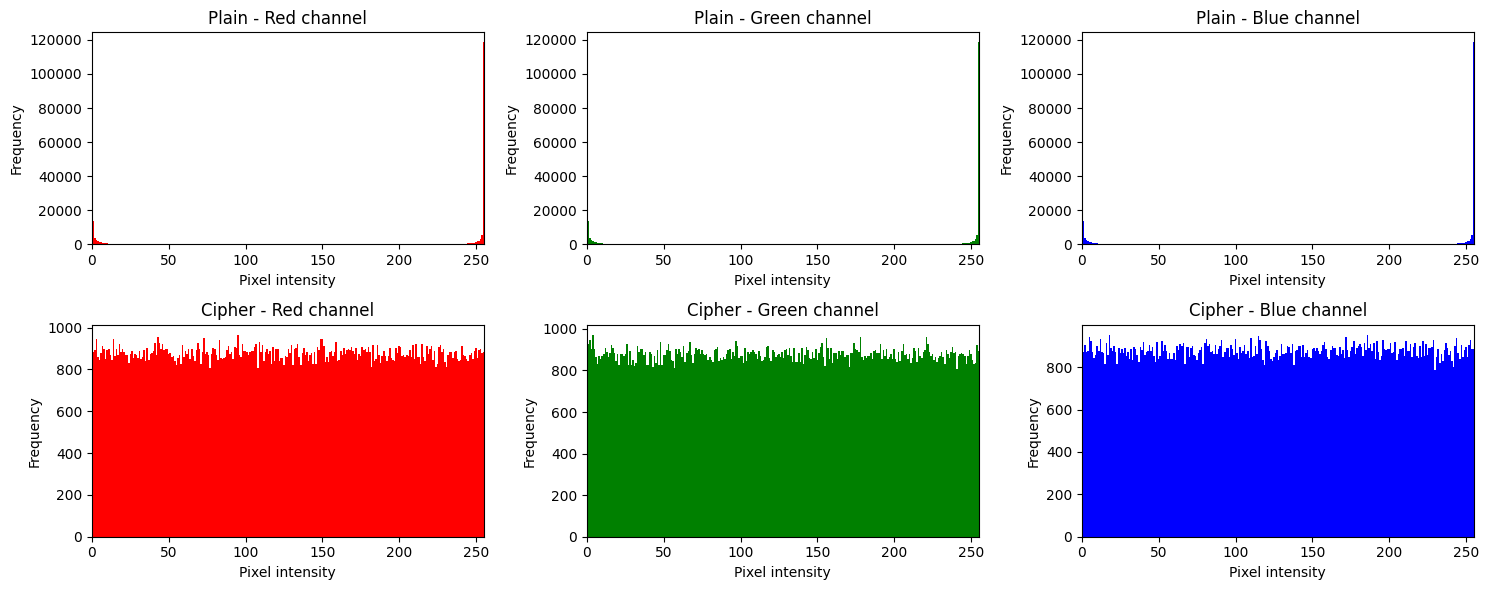

In [12]:
plot_channel_histograms(img, encrypted_img)

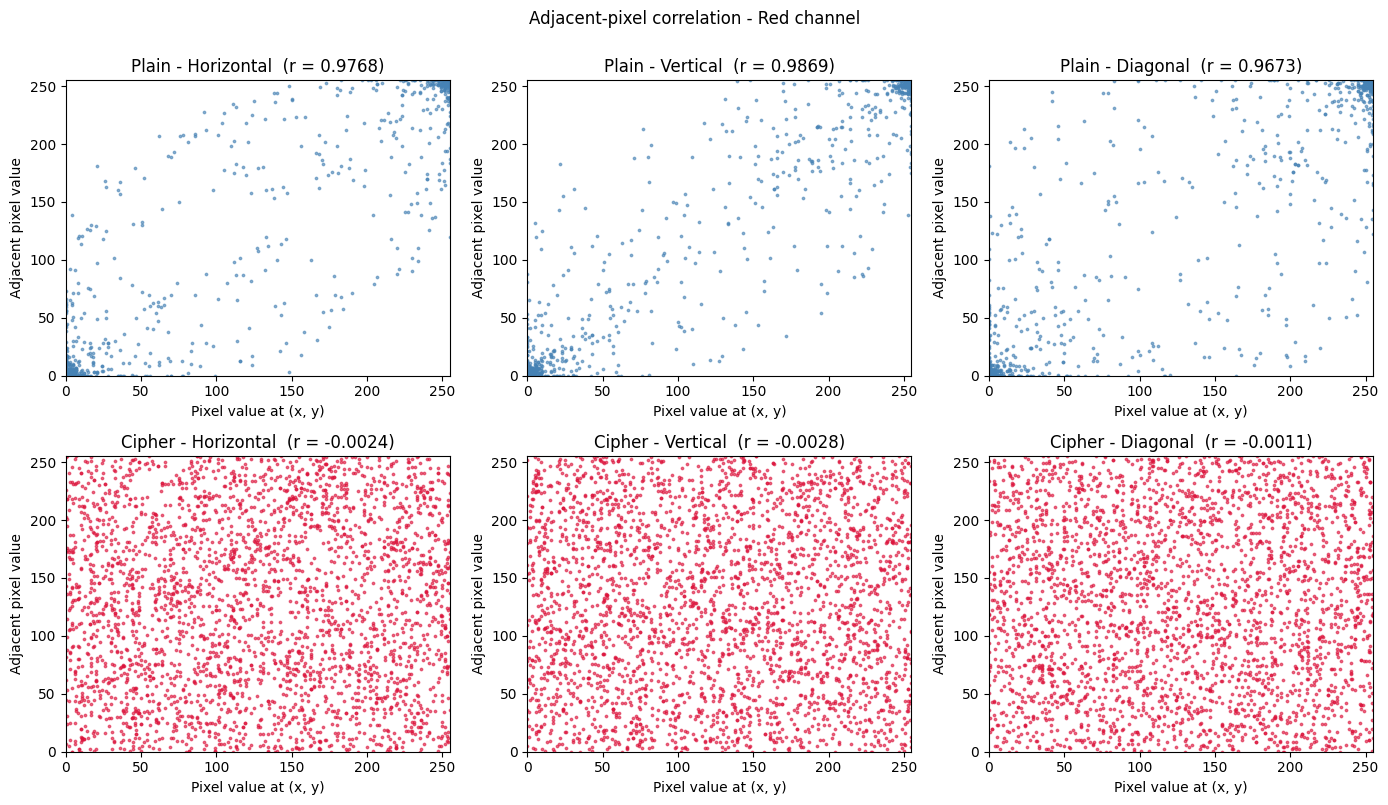

In [13]:
plot_correlation_scatter(img, encrypted_img, channel=0)

Channel Direction           Plain    Cipher
Red     Horizontal         0.9768   -0.0024
Red     Vertical           0.9869   -0.0028
Red     Diagonal           0.9673   -0.0011
Red     Anti-diagonal      0.9683   -0.0003
Green   Horizontal         0.9768    0.0026
Green   Vertical           0.9869   -0.0020
Green   Diagonal           0.9673    0.0010
Green   Anti-diagonal      0.9683    0.0016
Blue    Horizontal         0.9768    0.0019
Blue    Vertical           0.9869   -0.0023
Blue    Diagonal           0.9673    0.0024
Blue    Anti-diagonal      0.9683    0.0005


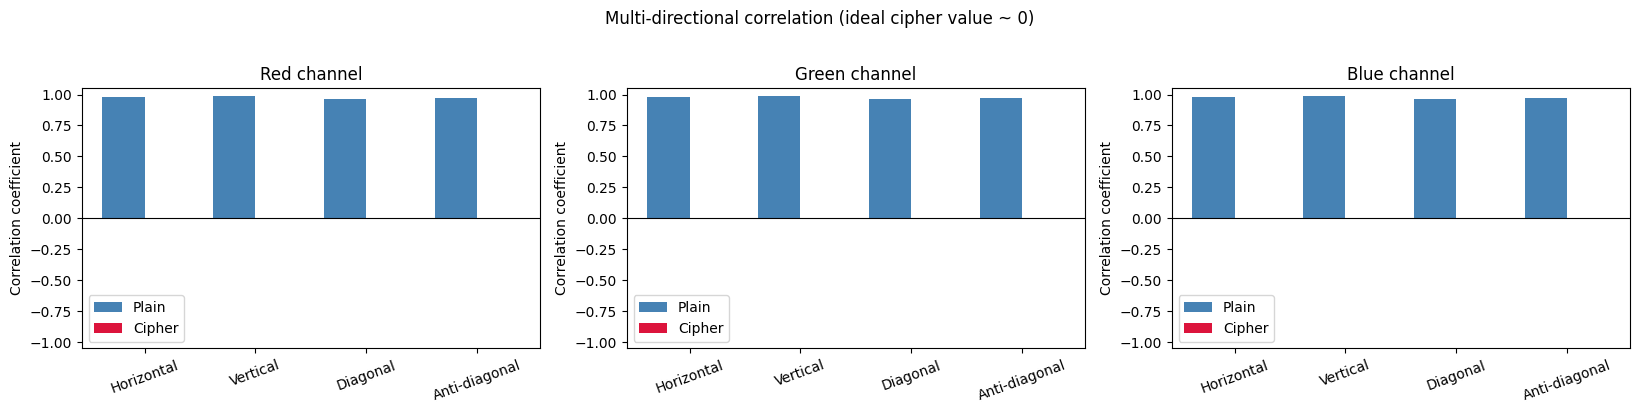

In [14]:
plot_multidirectional_correlation(img, encrypted_img)

Red      plain = 3.4080   cipher = 7.9992   (ideal = 8)
Green    plain = 3.4080   cipher = 7.9992   (ideal = 8)
Blue     plain = 3.4080   cipher = 7.9991   (ideal = 8)
Overall  plain = 3.4080   cipher = 7.9997   (ideal = 8)


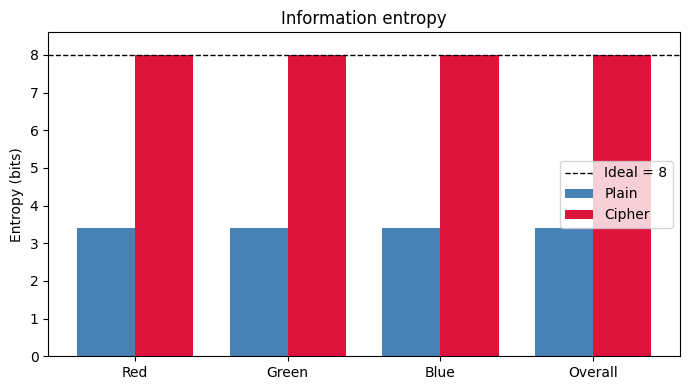

In [15]:
plot_entropy(img, encrypted_img)



NPCR mean = 99.8103 %   (ideal 99.6094 %)
UACI mean = 31.3023 %   (ideal 33.4635 %)


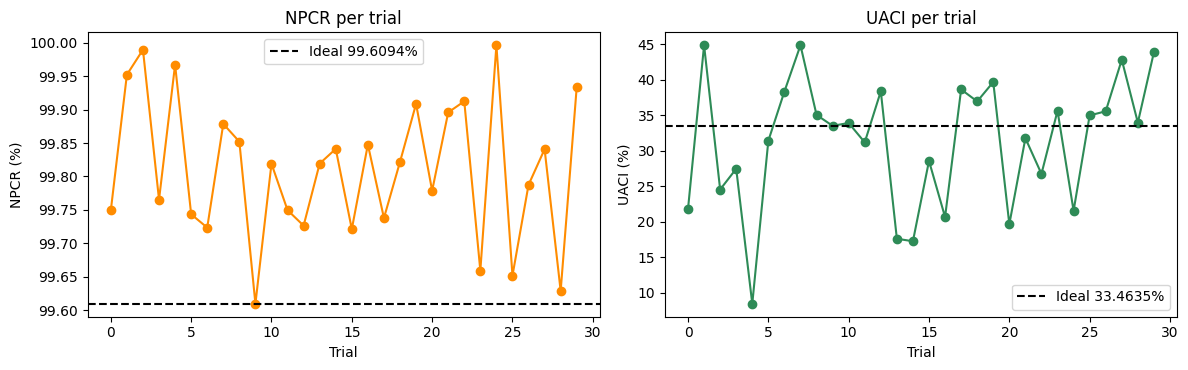

In [16]:
plot_npcr_uaci(img, encrypted_img, Encrypt, n_trials=30)